In [1]:
import pandas as pd

df = pd.read_csv("../data/ktas_clean.csv")

df.shape

(1267, 15)

In [ ]:
#Critical becomes 0, Urgent 1 and Stable 2.
X = df.drop(columns=["severity", "Chief_complain"])

tier_to_number = {"Critical": 0, "Urgent": 1, "Stable": 2}
y = df["severity"].map(tier_to_number)

X.shape, y.value_counts()

((1267, 13),
 severity
 2    534
 1    487
 0    246
 Name: count, dtype: int64)

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train.shape, X_test.shape

((1013, 13), (254, 13))

In [ ]:
#train the model
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

weights = compute_sample_weight("balanced", y_train)

model = XGBClassifier(
   n_estimators=300,
   max_depth=4,
   learning_rate=0.05,
   random_state=42,
)

model.fit(X_train, y_train, sample_weight=weights)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [ ]:
#test on the 254 patients
from sklearn.metrics import classification_report, confusion_matrix

predictions = model.predict(X_test)
names = ["Critical", "Urgent", "Stable"]

print(classification_report(y_test, predictions, target_names=names))
print(confusion_matrix(y_test, predictions))

              precision    recall  f1-score   support

    Critical       0.45      0.53      0.49        49
      Urgent       0.62      0.60      0.61        98
      Stable       0.69      0.65      0.67       107

    accuracy                           0.61       254
   macro avg       0.59      0.60      0.59       254
weighted avg       0.62      0.61      0.61       254

[[26 13 10]
 [18 59 21]
 [14 23 70]]


In [6]:
df["Chief_complain"].nunique()

417

In [7]:
df["Chief_complain"].value_counts().head(20)

Chief_complain
abd pain            72
dyspnea             60
dizziness           59
fever               45
ant. chest pain     44
Open Wound          31
headache            30
mental change       22
epigastric pain     22
general weakness    21
pain, chest         16
vomiting            16
hematemesis         14
Abd. pain           12
Left chest pain     12
Lt flank pain       11
abdomen pain        10
dysarthria          10
syncope             10
facial injury        9
Name: count, dtype: int64

In [ ]:
#comparison table to find the best hyperparameters for the model
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

cv = StratifiedKFold(5, shuffle=True, random_state=42)
critical_recall = make_scorer(recall_score, labels=[0], average="macro")

rows = []
for depth in [2, 3, 4, 6]:
    for trees in [100, 300]:
        m = XGBClassifier(n_estimators=trees, max_depth=depth,
                          learning_rate=0.05, random_state=42)
        s = cross_validate(m, X_train, y_train, cv=cv,
                           scoring={"acc": "accuracy", "crit": critical_recall},
                           params={"sample_weight": weights})
        rows.append((depth, trees,
                     round(s["test_acc"].mean(), 3),
                     round(s["test_crit"].mean(), 3)))

results = pd.DataFrame(rows, columns=["max_depth", "n_estimators",
                                      "accuracy", "critical_recall"])
results

,max_depth,n_estimators,accuracy,critical_recall
0,2,100,0.624,0.513
1,2,300,0.629,0.569
2,3,100,0.639,0.574
3,3,300,0.626,0.569
4,4,100,0.629,0.559
5,4,300,0.610,0.544
6,6,100,0.615,0.544
7,6,300,0.603,0.493


In [9]:
import re

s = df["Chief_complain"].str.lower().str.strip()

RULES = [
    ("chest_pain", r"chest|palpitation|angina"),
    ("abdominal_pain", r"abd|epigast|stomach|flank|rlq|llq|ruq|luq|groin"),
    ("breathing", r"dyspnea|dyspnoea|shortness|sob|cough|breath|wheez|hemoptysis"),
    ("neuro", r"dizz|vertigo|mental|conscious|syncope|seizure|convuls|dysarthria|weakness|palsy|paresis|hemipar|loc$|^loc|amnesia|blurred|vision|numb|stroke|paralys|aphasia|confus|drows"),
    ("fever", r"fever|chill"),
    ("skin_ent_urinary_psych", r"rash|urticar|itch|epistaxis|nose|throat|ear|dysuria|urin|void|hematuria|anxiety|suicid|psych|agitat|violence|myalgia|cpr|ascites|catheter"),
    ("headache", r"headache|head ache|^ha$"),
    ("bleeding_gi", r"hematem|melena|hematochezia|bloody|bleed|vomit|diarrh|nausea|constipat"),
    ("injury_wound", r"wound|laceration|injur|trauma|fall|fracture|burn|bite|contusion|sprain|swelling|cut|abrasion"),
    ("pain_other", r"pain|ache"),
    ("unreadable", r"^[?\s]+$"),
]

def group_complaint(text):
    for name, pattern in RULES:
        if re.search(pattern, text):
            return name
    return "other"

df["complaint_group"] = s.apply(group_complaint)
df["complaint_group"].value_counts()

complaint_group
abdominal_pain            223
neuro                     222
injury_wound              125
pain_other                121
chest_pain                111
other                     107
bleeding_gi                85
skin_ent_urinary_psych     83
breathing                  74
fever                      49
headache                   46
unreadable                 21
Name: count, dtype: int64

In [ ]:
#feed the model with the new complaint groups. The model will now have 12 more columns, one for each complaint group.
base_cols = ["Sex", "Age", "Arrival mode", "Injury", "Mental", "Pain",
             "NRS_pain", "SBP", "DBP", "HR", "RR", "BT", "Saturation"]

X = pd.concat(
    [df[base_cols], pd.get_dummies(df["complaint_group"], prefix="cc").astype(int)],
    axis=1,
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
weights = compute_sample_weight("balanced", y_train)

X.shape

(1267, 25)

In [ ]:
#comparison table to find the best hyperparameters for the model but now with the new complaint groups
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

cv = StratifiedKFold(5, shuffle=True, random_state=42)
critical_recall = make_scorer(recall_score, labels=[0], average="macro")

rows = []
for depth in [2, 3, 4, 6]:
    for trees in [100, 300]:
        m = XGBClassifier(n_estimators=trees, max_depth=depth,
                          learning_rate=0.05, random_state=42)
        s = cross_validate(m, X_train, y_train, cv=cv,
                           scoring={"acc": "accuracy", "crit": critical_recall},
                           params={"sample_weight": weights})
        rows.append((depth, trees,
                     round(s["test_acc"].mean(), 3),
                     round(s["test_crit"].mean(), 3)))

results = pd.DataFrame(rows, columns=["max_depth", "n_estimators",
                                      "accuracy", "critical_recall"])
results

,max_depth,n_estimators,accuracy,critical_recall
0,2,100,0.726,0.701
1,2,300,0.731,0.686
2,3,100,0.722,0.665
3,3,300,0.733,0.681
4,4,100,0.722,0.665
5,4,300,0.726,0.640
6,6,100,0.718,0.650
7,6,300,0.723,0.630


In [14]:
final_model = XGBClassifier(
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    base_score=0.5,
    random_state=42,
)
final_model.fit(X_train, y_train, sample_weight=weights)

predictions = final_model.predict(X_test)
names = ["Critical", "Urgent", "Stable"]

print(classification_report(y_test, predictions, target_names=names))
print(confusion_matrix(y_test, predictions))

              precision    recall  f1-score   support

    Critical       0.57      0.63      0.60        49
      Urgent       0.81      0.62      0.71        98
      Stable       0.78      0.92      0.84       107

    accuracy                           0.75       254
   macro avg       0.72      0.72      0.72       254
weighted avg       0.75      0.75      0.74       254

[[31 12  6]
 [16 61 21]
 [ 7  2 98]]


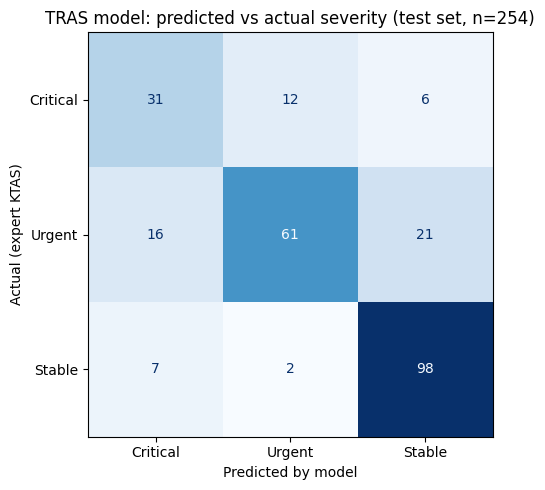

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = np.array([[31, 12, 6],
               [16, 61, 21],
               [7, 2, 98]])
labels = ["Critical", "Urgent", "Stable"]

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("TRAS model: predicted vs actual severity (test set, n=254)")
ax.set_xlabel("Predicted by model")
ax.set_ylabel("Actual (expert KTAS)")
plt.tight_layout()
plt.savefig("../confusion_matrix.png", dpi=200)   
plt.show()

In [17]:
import xgboost as xgb

contrib = final_model.get_booster().predict(xgb.DMatrix(X_test), pred_contribs=True)
contrib.shape

(254, 3, 26)

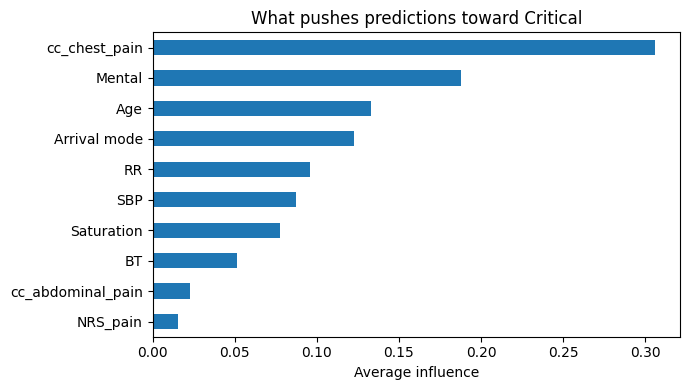

In [ ]:
#shows which cells push the model toward predicting Critical. The higher the value, the more that feature pushes the model toward Critical.
import matplotlib.pyplot as plt

critical = contrib[:, 0, :-1]
importance = pd.Series(abs(critical).mean(axis=0), index=X_test.columns)
importance = importance.sort_values().tail(10)

importance.plot(kind="barh", figsize=(7, 4))
plt.title("What pushes predictions toward Critical")
plt.xlabel("Average influence")
plt.tight_layout()
plt.show()

In [19]:
names = ["Critical", "Urgent", "Stable"]

def describe(feature, value):
    if feature.startswith("cc_"):
        group = feature[3:].replace("_", " ")
        return f"complaint group is {'' if value == 1 else 'not '}'{group}'"
    return f"{feature} = {value:g}"

def explain_patient(i, top=4):
    row = X_test.iloc[[i]]
    probs = final_model.predict_proba(row)[0]
    pred = int(probs.argmax())
    print(f"Patient #{i}: predicted {names[pred]} ({probs[pred]:.0%}); actual: {names[int(y_test.iloc[i])]}")
    scores = pd.Series(contrib[i, pred, :-1], index=X_test.columns)
    strongest = scores.reindex(scores.abs().sort_values(ascending=False).index)[:top]
    for feature, score in strongest.items():
        direction = "toward" if score > 0 else "away from"
        print(f"  {describe(feature, row[feature].iloc[0])} -> pushes {direction} {names[pred]}")

explain_patient(0)
explain_patient(1)

Patient #0: predicted Stable (66%); actual: Stable
  complaint group is 'pain other' -> pushes toward Stable
  complaint group is not 'neuro' -> pushes toward Stable
  complaint group is not 'chest pain' -> pushes toward Stable
  Injury = 2 -> pushes toward Stable
Patient #1: predicted Urgent (53%); actual: Critical
  complaint group is 'breathing' -> pushes toward Urgent
  NRS_pain = 0 -> pushes toward Urgent
  complaint group is not 'abdominal pain' -> pushes away from Urgent
  BT = 37 -> pushes toward Urgent


In [20]:
names = ["Critical", "Urgent", "Stable"]

def describe(feature, value):
    if feature.startswith("cc_"):
        group = feature[3:].replace("_", " ")
        return f"complaint group is {'' if value == 1 else 'not '}'{group}'"
    return f"{feature} = {value:g}"

def explain_patient(i, top=4):
    row = X_test.iloc[[i]]
    probs = final_model.predict_proba(row)[0]
    pred = int(probs.argmax())
    print(f"Patient #{i}: predicted {names[pred]} ({probs[pred]:.0%}); actual: {names[int(y_test.iloc[i])]}")
    scores = pd.Series(contrib[i, pred, :-1], index=X_test.columns)
    strongest = scores.reindex(scores.abs().sort_values(ascending=False).index)[:top]
    for feature, score in strongest.items():
        direction = "toward" if score > 0 else "away from"
        print(f"  {describe(feature, row[feature].iloc[0])} -> pushes {direction} {names[pred]}")

explain_patient(5)
explain_patient(12)

Patient #5: predicted Stable (66%); actual: Stable
  complaint group is not 'neuro' -> pushes toward Stable
  NRS_pain = 2 -> pushes toward Stable
  complaint group is not 'chest pain' -> pushes toward Stable
  complaint group is not 'breathing' -> pushes toward Stable
Patient #12: predicted Urgent (39%); actual: Urgent
  NRS_pain = 0 -> pushes toward Urgent
  BT = 36.2 -> pushes away from Urgent
  complaint group is not 'abdominal pain' -> pushes away from Urgent
  HR = 100 -> pushes away from Urgent


In [ ]:
#save the model and the feature columns to disk so that they can be used in the web app
import os, json

os.makedirs("../models", exist_ok=True)

final_model.save_model("../models/severity_model.json")

with open("../models/feature_columns.json", "w") as f:
    json.dump(list(X_train.columns), f)

list(X_train.columns)

['Sex',
 'Age',
 'Arrival mode',
 'Injury',
 'Mental',
 'Pain',
 'NRS_pain',
 'SBP',
 'DBP',
 'HR',
 'RR',
 'BT',
 'Saturation',
 'cc_abdominal_pain',
 'cc_bleeding_gi',
 'cc_breathing',
 'cc_chest_pain',
 'cc_fever',
 'cc_headache',
 'cc_injury_wound',
 'cc_neuro',
 'cc_other',
 'cc_pain_other',
 'cc_skin_ent_urinary_psych',
 'cc_unreadable']